# Data 
FROM README.txt

List of Attribute 
    This dataset is designed to support the development of automated classification models for user reviews in telemedicine applications. It also includes additional attributes, such as weight. The list of attributes is shown in the table below. 

Attribute Description 
- platform : Application distributor platform 
- app_name : Application name 
- rating : Application user satisfaction score  
- review : Application user review 
- sentiment : Data label (negative, neutral, positive) 
- weight : User review complexity label (uninformative, informative, complex) 

Value of the Data 
- The Weighted Telemedicine Sentiment Dataset contains 19,680 manually annotated Indonesian-language user reviews from three telemedicine applications, labeled with three sentiment classes (Positive, Neutral, Negative) and a weight attribute (Uninformative, Informative, Complex) indicating review informativeness. 
- The annotation was performed by two annotators following a documented guideline reviewed by a psychology expert, with inter-annotator agreement measured using Cohen's Kappa, which indicated substantial agreement (κ = 0.752), thereby enabling other researchers to assess label reliability. 
- Facilitates and supports experiments in advanced NLP technologies, including BERT, LSTM, and LLMs, such as the user review sentiment classification task. 
- This dataset introduces a weight attribute (Uninformative, Informative, Complex), which adds a crucial secondary dimension. This enables researchers to analyze not only what the user feels but also the substantive value of the review, thereby facilitating more advanced tasks such as Aspect-Based Sentiment Analysis (ABSA). On the other hand, this label can be enabled to curate the data, such as filtering uninformative reviews or studying the characteristics of complex user feedback, while telemedicine providers can use the labeled reviews to examine user-reported service issues. 

Data Annotation 
- The dataset was manually annotated by two annotators 

- A fundamental difference from the previous dataset lies in the manual annotation process, which was validated by Psychology experts, ensuring that the resulting annotations align with scientific psychological principles 

# Import Library

In [1]:
from pathlib import Path
import sys, os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import ftfy
from sklearn.model_selection import StratifiedGroupKFold
from collections import Counter
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
import emoji

import warnings
warnings.filterwarnings('ignore')

## Read CSV File & Initiating EDA

In [2]:
df = pd.read_csv('../data/raw/WeightedSentimentTelemedicineDataset.csv', low_memory=False)
df["orig_id"] = df.index

## A. Data Description

In [3]:
df.head(5)

,platform,app_name,rating,review,sentiment,weight,orig_id
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE,0
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE,1
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE,2
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE,3
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE,4


In [4]:
df['platform'].value_counts()

platform
Play Store    19680
Name: count, dtype: int64

In [5]:
df['app_name'].value_counts()

app_name
Alodokter —Chat Bersama Dokter    7602
Halodoc: Dokter, Obat & Lab       7295
KlikDokter: Jaga Sehatmu          4783
Name: count, dtype: int64

In [6]:
df['weight'].value_counts()

weight
UNINFORMATIVE    16572
INFORMATIVE       2718
COMPLEX            390
Name: count, dtype: int64

### A.1 Null value & Duplicate detection

In [7]:
df['review_character_length'] = df['review'].str.len()
df['review_word_count'] = df['review'].str.split().str.len()

In [8]:
# Check total duplicates
print(df['review'].str.lower().str.strip().duplicated().sum())

1305


In [9]:
# Check Missing Value
null_reviews = df[df['review'].isna()].copy()
print(f"Total NaN reviews in df: {len(null_reviews)}")

Total NaN reviews in df: 52


In [10]:
# Inspect the metadata of these 52 rows
display(null_reviews[['app_name', 'rating', 'sentiment', 'weight', 'review']])

# Check what was originally written in the raw CSV file
raw = pd.read_csv('../data/raw/WeightedSentimentTelemedicineDataset.csv', 
                        keep_default_na=False, low_memory=False)

# Get the exact strings from the raw file for these 52 row indexes
raw_values = raw.loc[null_reviews.index, 'review']
print("\nExact text in raw CSV for these rows:")
print(raw_values.value_counts(dropna=False))

,app_name,rating,sentiment,weight,review
3390,Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,NaN
3458,Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,NaN
3482,Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,NaN
3915,"Halodoc: Dokter, Obat & Lab",1,NEGATIVE,UNINFORMATIVE,NaN
6792,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
7079,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
7083,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
7093,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
8149,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
8232,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN



Exact text in raw CSV for these rows:
review
    52
Name: count, dtype: int64


We wil drop this missing value from the data.

### A.2 'weight' column overview

In [11]:
df[df['weight'] == 'UNINFORMATIVE']

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE,0,3.0,1.0
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE,1,101.0,18.0
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE,2,156.0,25.0
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE,3,16.0,2.0
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE,4,289.0,48.0
...,...,...,...,...,...,...,...,...,...
19675,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah mngetahui tntng kshatan gaya hdup ...,POSITIVE,UNINFORMATIVE,19675,54.0,8.0
19676,Play Store,KlikDokter: Jaga Sehatmu,5,Semua ulasan,POSITIVE,UNINFORMATIVE,19676,12.0,2.0
19677,Play Store,KlikDokter: Jaga Sehatmu,4,BAguz,POSITIVE,UNINFORMATIVE,19677,5.0,1.0
19678,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah kita jika mau berkonsultasi dengan...,POSITIVE,UNINFORMATIVE,19678,63.0,9.0


In [12]:
df[df['weight'] == 'INFORMATIVE'].head(5)

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
9,Play Store,Alodokter —Chat Bersama Dokter,5,aplikasi ini engga amanah saya order yang inst...,NEGATIVE,INFORMATIVE,9,148.0,25.0
11,Play Store,Alodokter —Chat Bersama Dokter,1,syaa sudah konsul dokter SP.M di kasih resep o...,NEGATIVE,INFORMATIVE,11,337.0,58.0
16,Play Store,Alodokter —Chat Bersama Dokter,5,kapok berobat d Alo dokter obat sudah d beli G...,NEGATIVE,INFORMATIVE,16,98.0,18.0
29,Play Store,Alodokter —Chat Bersama Dokter,5,"GK bisa daftar, bahaya ini. mohon dicoba kemba...",NEGATIVE,INFORMATIVE,29,88.0,13.0
39,Play Store,Alodokter —Chat Bersama Dokter,5,"mau tanya, ini konsul doang atau konsul terus ...",NEUTRAL,INFORMATIVE,39,106.0,17.0


In [13]:
df[df['weight'] == 'COMPLEX'].head(5)

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
42,Play Store,Alodokter —Chat Bersama Dokter,1,"setiap chat dokter, selalu je scroll otomatis ...",NEGATIVE,COMPLEX,42,208.0,32.0
49,Play Store,Alodokter —Chat Bersama Dokter,4,tolong memberikan deskripsi di aplikasi nya se...,POSITIVE,COMPLEX,49,140.0,19.0
82,Play Store,Alodokter —Chat Bersama Dokter,5,belum jg ngmong. udah habis masa pembayaran ny...,NEGATIVE,COMPLEX,82,230.0,40.0
96,Play Store,Alodokter —Chat Bersama Dokter,5,"Sangat terbantu dengan resep dokternya, pengir...",POSITIVE,COMPLEX,96,404.0,59.0
119,Play Store,Alodokter —Chat Bersama Dokter,5,tingkatkan lagi pelyananan supaya semua bisa d...,POSITIVE,COMPLEX,119,53.0,8.0


In [14]:
df.groupby('weight')['review_character_length'].describe().round(3).T

weight,COMPLEX,INFORMATIVE,UNINFORMATIVE
count,390.000,2718.000,16520.000
mean,307.359,192.678,52.208
std,116.397,99.450,42.546
min,53.000,13.000,2.000
25%,218.250,123.000,22.000
50%,287.500,172.000,40.000
75%,408.750,236.000,71.000
max,529.000,595.000,499.000


In [15]:
df[(df['review_character_length'] > 71) & (df['weight'] == 'UNINFORMATIVE')]

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE,1,101.0,18.0
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE,2,156.0,25.0
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE,4,289.0,48.0
5,Play Store,Alodokter —Chat Bersama Dokter,2,dokternya responnya lama .... ( Semoga bisa di...,NEGATIVE,UNINFORMATIVE,5,99.0,15.0
13,Play Store,Alodokter —Chat Bersama Dokter,1,sedikit kecewa. karena psikolog saya yg salah ...,NEGATIVE,UNINFORMATIVE,13,156.0,24.0
...,...,...,...,...,...,...,...,...,...
19640,Play Store,KlikDokter: Jaga Sehatmu,5,sangat bermanfaat sekali buat kita dn keluarga...,POSITIVE,UNINFORMATIVE,19640,108.0,16.0
19648,Play Store,KlikDokter: Jaga Sehatmu,5,Sangat penting buat saya untuk mengetahui tent...,POSITIVE,UNINFORMATIVE,19648,98.0,14.0
19650,Play Store,KlikDokter: Jaga Sehatmu,4,Dengan aplikasi ini saya lebih mudah untuk men...,POSITIVE,UNINFORMATIVE,19650,82.0,11.0
19657,Play Store,KlikDokter: Jaga Sehatmu,4,Trimakasih banyak klinik dokter.. saya sangat ...,POSITIVE,UNINFORMATIVE,19657,136.0,21.0


In [16]:
df.groupby('weight')['rating'].describe().T

weight,COMPLEX,INFORMATIVE,UNINFORMATIVE
count,390.000000,2718.000000,16572.000000
mean,2.923077,3.278514,4.292300
std,1.698095,1.823674,1.403851
min,1.000000,1.000000,1.000000
25%,1.000000,1.000000,5.000000
50%,3.000000,4.000000,5.000000
75%,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000


Kebanyakan kolom uninformative adalah rating positive, bahkan di Q 25% sudah didominasi di 5, sedangkan informative memiliki rating positive namun tidak sempurna, dan complex cenderung memiliki rating negative.

### A.3 'sentiment' column overview 

In [17]:
df['sentiment'].value_counts()

sentiment
POSITIVE    14748
NEGATIVE     4221
NEUTRAL       711
Name: count, dtype: int64

In [18]:
df.groupby('sentiment')['rating'].value_counts().T

sentiment  rating
NEGATIVE   1          3200
           2           457
           3           414
           4            79
           5            71
NEUTRAL    5           329
           3           187
           4            96
           2            79
           1            20
POSITIVE   5         13612
           4           990
           3            79
           2            64
           1             3
Name: count, dtype: int64

In [19]:
df.groupby('app_name')['sentiment'].value_counts().T

app_name                        sentiment
Alodokter —Chat Bersama Dokter  POSITIVE     4915
                                NEGATIVE     2260
                                NEUTRAL       427
Halodoc: Dokter, Obat & Lab     POSITIVE     6198
                                NEGATIVE     1030
                                NEUTRAL        67
KlikDokter: Jaga Sehatmu        POSITIVE     3635
                                NEGATIVE      931
                                NEUTRAL       217
Name: count, dtype: int64

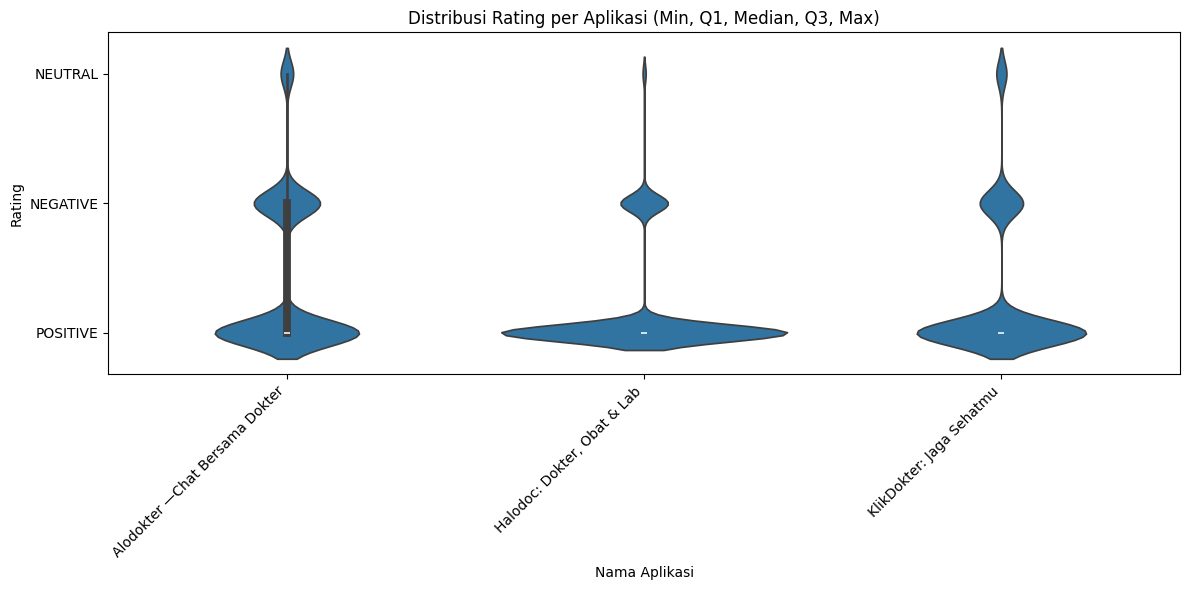

In [20]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='app_name', y='sentiment')

plt.title('Distribusi Rating per Aplikasi (Min, Q1, Median, Q3, Max)')
plt.xlabel('Nama Aplikasi')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### A.3.1 (!!REVIEW THIS!!) Inspecting Neutral Sentiment

In [21]:
df['sentiment'].value_counts()

sentiment
POSITIVE    14748
NEGATIVE     4221
NEUTRAL       711
Name: count, dtype: int64

In [22]:
df.groupby('app_name')['sentiment'].value_counts()

app_name                        sentiment
Alodokter —Chat Bersama Dokter  POSITIVE     4915
                                NEGATIVE     2260
                                NEUTRAL       427
Halodoc: Dokter, Obat & Lab     POSITIVE     6198
                                NEGATIVE     1030
                                NEUTRAL        67
KlikDokter: Jaga Sehatmu        POSITIVE     3635
                                NEGATIVE      931
                                NEUTRAL       217
Name: count, dtype: int64

In [23]:
df.columns

Index(['platform', 'app_name', 'rating', 'review', 'sentiment', 'weight',
       'orig_id', 'review_character_length', 'review_word_count'],
      dtype='object')

In [24]:
temp = df[(df['app_name'] == 'Alodokter —Chat Bersama Dokter') & (df['sentiment'] == 'NEUTRAL')]
pd.set_option("display.max_colwidth", None)
display(temp[['weight', 'review', 'rating', 'sentiment']])



,weight,review,rating,sentiment
0,UNINFORMATIVE,oke,5,NEUTRAL
4,UNINFORMATIVE,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan",5,NEUTRAL
8,UNINFORMATIVE,good job,5,NEUTRAL
10,UNINFORMATIVE,ok,5,NEUTRAL
12,UNINFORMATIVE,baik,4,NEUTRAL
...,...,...,...,...
9408,UNINFORMATIVE,blngapa,5,NEUTRAL
9423,UNINFORMATIVE,cari tau tentang kesehatan.,4,NEUTRAL
9427,UNINFORMATIVE,Apa salep aman anti septik buat bisul?,5,NEUTRAL
9558,INFORMATIVE,Anak saya udah 10 hari tapi badannya masih panas dan klu panas kakinya terasa dingin dan tangannya juga dingin minumin parasetamol dan amozsilin masih turun naik panasnya apa masalahnya dan apa obat yang bagus? . Apa obat yang bagus buat penderita tipes,5,NEUTRAL


In [25]:
len(df[(df['app_name'] == 'Alodokter —Chat Bersama Dokter') & (df['sentiment'] == 'NEUTRAL')])

427

In [26]:
'''
positive_keywords = [
    "oke", "ok", "okee", "okey", "good job", "goodjob", 
    "baik", 'baikk', 'baiik', "bagus", "sip", 'baik dokternya', 'ty',
    "siap", "mantap", 'good', 'terima kasih', 'nice', 'thank you', 'terimakasih',
    'trimakasih', 'sehat selalu', 'sangat berguna', 'okk', 'bagus', 'approved',
    'like', 'wow', 'terimaksih', 'makasih',
]

# 2. Buat regex pattern untuk mencocokkan kata (case-insensitive & menghapus spasi/karakter berlebih)
pattern = r"\b(" + "|".join(positive_keywords) + r")\b"

# 3. Tentukan kondisi: teks cocok dengan pattern DAN rating > 3
condition = df["review"].str.strip().str.lower().str.contains(
    pattern, regex=True, na=False
) & (df["rating"] > 3)

# 4. Ubah label sentimen menjadi POSITIVE jika memenuhi kondisi
df.loc[condition, "sentiment"] = "POSITIVE"
'''

'\npositive_keywords = [\n    "oke", "ok", "okee", "okey", "good job", "goodjob", \n    "baik", \'baikk\', \'baiik\', "bagus", "sip", \'baik dokternya\', \'ty\',\n    "siap", "mantap", \'good\', \'terima kasih\', \'nice\', \'thank you\', \'terimakasih\',\n    \'trimakasih\', \'sehat selalu\', \'sangat berguna\', \'okk\', \'bagus\', \'approved\',\n    \'like\', \'wow\', \'terimaksih\', \'makasih\',\n]\n\n# 2. Buat regex pattern untuk mencocokkan kata (case-insensitive & menghapus spasi/karakter berlebih)\npattern = r"\x08(" + "|".join(positive_keywords) + r")\x08"\n\n# 3. Tentukan kondisi: teks cocok dengan pattern DAN rating > 3\ncondition = df["review"].str.strip().str.lower().str.contains(\n    pattern, regex=True, na=False\n) & (df["rating"] > 3)\n\n# 4. Ubah label sentimen menjadi POSITIVE jika memenuhi kondisi\ndf.loc[condition, "sentiment"] = "POSITIVE"\n'

In [27]:
df.loc[104]

platform                                       Play Store
app_name                   Alodokter —Chat Bersama Dokter
rating                                                  5
review                                              baiik
sentiment                                         NEUTRAL
weight                                      UNINFORMATIVE
orig_id                                               104
review_character_length                               5.0
review_word_count                                     1.0
Name: 104, dtype: object

In [28]:
len(df[(df['app_name'] == 'Alodokter —Chat Bersama Dokter') & (df['sentiment'] == 'NEUTRAL')])

427

In [29]:
temp = df[df['sentiment'] == 'NEUTRAL']
display(temp[['weight', 'review', 'rating', 'sentiment']])

,weight,review,rating,sentiment
0,UNINFORMATIVE,oke,5,NEUTRAL
4,UNINFORMATIVE,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan",5,NEUTRAL
8,UNINFORMATIVE,good job,5,NEUTRAL
10,UNINFORMATIVE,ok,5,NEUTRAL
12,UNINFORMATIVE,baik,4,NEUTRAL
...,...,...,...,...
19649,UNINFORMATIVE,Siiiiiip,5,NEUTRAL
19658,UNINFORMATIVE,mencoba tau informasi kesehatan,4,NEUTRAL
19659,UNINFORMATIVE,Lumaya,4,NEUTRAL
19665,UNINFORMATIVE,Bru cba.',5,NEUTRAL


In [30]:
temp = df[df['review'].str.contains(r'(?=.*\bapa\b)(?=.*\?)', regex=True, na=False, case=False)]
len(temp)

125

In [31]:
pd.set_option("display.max_colwidth", 100)

### A.4 Rating score overview 
based on each App review

In [32]:
df.groupby('app_name')['rating'].describe().T

app_name,Alodokter —Chat Bersama Dokter,"Halodoc: Dokter, Obat & Lab",KlikDokter: Jaga Sehatmu
count,7602.000000,7295.000000,4783.000000
mean,3.830571,4.426456,4.133807
std,1.696626,1.297648,1.468074
min,1.000000,1.000000,1.000000
25%,2.000000,5.000000,4.000000
50%,5.000000,5.000000,5.000000
75%,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000


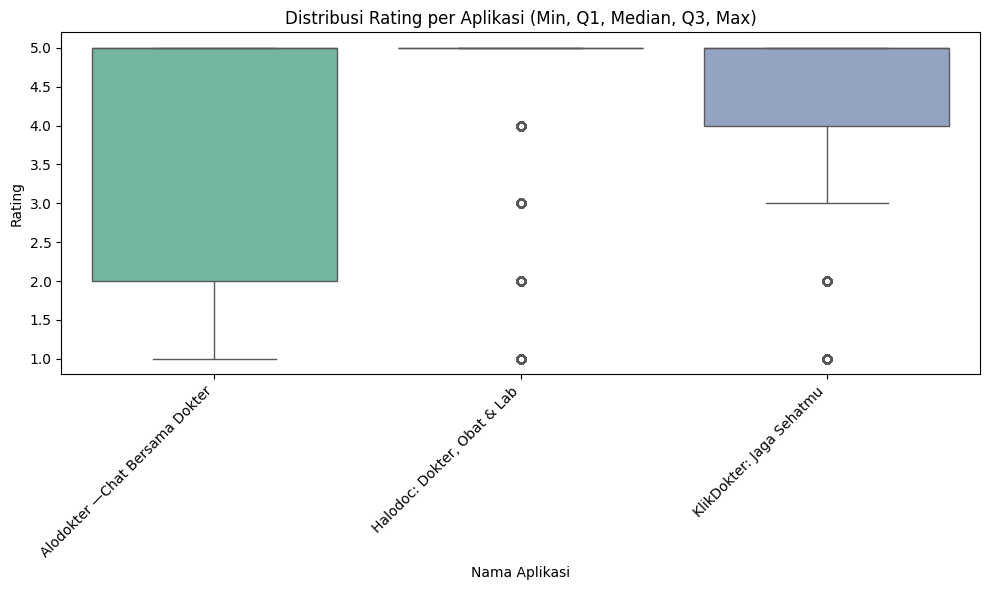

In [33]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='app_name', y='rating', palette='Set2')

plt.title('Distribusi Rating per Aplikasi (Min, Q1, Median, Q3, Max)')
plt.xlabel('Nama Aplikasi')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### A.5 Potential Anomaly

In [34]:
df[(df['sentiment'] == 'NEGATIVE') & (df['rating'] > 3)]

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
9,Play Store,Alodokter —Chat Bersama Dokter,5,"aplikasi ini engga amanah saya order yang instan tapi di kirim esok hari. aneh, seharusnya kalau...",NEGATIVE,INFORMATIVE,9,148.0,25.0
16,Play Store,Alodokter —Chat Bersama Dokter,5,kapok berobat d Alo dokter obat sudah d beli GK d kirim obat buat kesembuhan ngirim nya sembrono,NEGATIVE,INFORMATIVE,16,98.0,18.0
29,Play Store,Alodokter —Chat Bersama Dokter,5,"GK bisa daftar, bahaya ini. mohon dicoba kembali waktu daftar,kayak ngambil data ajaaa.",NEGATIVE,INFORMATIVE,29,88.0,13.0
40,Play Store,Alodokter —Chat Bersama Dokter,4,gak ada pembayaran lewat E-walet dana,NEGATIVE,UNINFORMATIVE,40,37.0,6.0
68,Play Store,Alodokter —Chat Bersama Dokter,5,"jangan mau berlangganan ,pembohong katanya unlimited tapi tetap di batasi,,maunya aplikasi ini k...",NEGATIVE,INFORMATIVE,68,323.0,45.0
...,...,...,...,...,...,...,...,...,...
17952,Play Store,KlikDokter: Jaga Sehatmu,4,Waktu konsultasi kurang lama.,NEGATIVE,INFORMATIVE,17952,29.0,4.0
18858,Play Store,KlikDokter: Jaga Sehatmu,4,"saya sudah daftar ,tapi kode verifikasi tidak di kirim kirim.",NEGATIVE,UNINFORMATIVE,18858,61.0,10.0
19035,Play Store,KlikDokter: Jaga Sehatmu,4,tlng jwbany lbih dipejlas,NEGATIVE,INFORMATIVE,19035,25.0,4.0
19292,Play Store,KlikDokter: Jaga Sehatmu,5,Koyok taek,NEGATIVE,UNINFORMATIVE,19292,10.0,2.0


### A.6 Sentiment x Weight overview

In [35]:
# 1. Sentiment x weight
print(pd.crosstab(df['sentiment'], df['weight'], margins=True))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE    All
sentiment                                            
NEGATIVE       213         1223           2785   4221
NEUTRAL         40          104            567    711
POSITIVE       137         1391          13220  14748
All            390         2718          16572  19680


In [36]:
print(pd.crosstab(df['sentiment'], df['weight'], normalize='columns').round(3))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE
sentiment                                     
NEGATIVE     0.546        0.450          0.168
NEUTRAL      0.103        0.038          0.034
POSITIVE     0.351        0.512          0.798


In [37]:
# 2. Weight per aplikasi
print(pd.crosstab(df['app_name'], df['weight'], normalize='index').round(3))

weight                          COMPLEX  INFORMATIVE  UNINFORMATIVE
app_name                                                           
Alodokter —Chat Bersama Dokter    0.022        0.137          0.842
Halodoc: Dokter, Obat & Lab       0.017        0.121          0.862
KlikDokter: Jaga Sehatmu          0.021        0.167          0.812


In [38]:
print(df.groupby('weight')['review_word_count'].describe())

                 count       mean        std  min   25%   50%   75%    max
weight                                                                    
COMPLEX          390.0  47.866667  18.721684  8.0  33.0  45.0  63.0   89.0
INFORMATIVE     2718.0  30.149375  16.189954  2.0  18.0  26.0  37.0  111.0
UNINFORMATIVE  16520.0   7.930872   6.737514  1.0   3.0   6.0  11.0   90.0


In [39]:
# 4. Weight di hard subset
hard = df[
    (df['sentiment'] == 'NEUTRAL') |
    ((df['sentiment'] == 'NEGATIVE') & (df['rating'] >= 4)) |
    ((df['sentiment'] == 'POSITIVE') & (df['rating'] <= 2))
]
print(pd.crosstab(hard['sentiment'], hard['weight']))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE
sentiment                                     
NEGATIVE        22           52             76
NEUTRAL         40          104            567
POSITIVE         4           19             44


In [40]:
print(f"Review length dist: \n{df['review_character_length'].describe()}")

Review length dist: 
count    19628.000000
mean        76.729264
std         81.154154
min          2.000000
25%         25.000000
50%         48.000000
75%         98.000000
max        595.000000
Name: review_character_length, dtype: float64


In [41]:
neg_words = {'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tapi', 'tetapi', 'namun'}

def has_neg(text):
    return any(t in neg_words for t in str(text).lower().split())

df['has_neg'] = df['review'].map(has_neg)
print(df['has_neg'].mean())                                # proporsi review yang kehilangan negasi
print(df.groupby('sentiment')['has_neg'].mean().round(3))  # per kelas

0.1410569105691057
sentiment
NEGATIVE    0.410
NEUTRAL     0.159
POSITIVE    0.063
Name: has_neg, dtype: float64


## B. Text Cleaning & Normalizing

Build the slang list from train only. The audit uses all of df. Slang still in your output: tpi, tidk, mngetahui, baguz.

In [42]:
ROOT_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT_DIR))

### B.1 Freeze The Split

In [43]:
# Path settings
SPLIT_DIR = Path('../data/splits')
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = SPLIT_DIR / 'split_ids.csv'

# Function for Stratified Group Split
def split_stratified_group(y, groups, test_size=0.10, random_state=42):
    n_splits = max(2, int(round(1.0 / test_size)))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    train_idx, test_idx = next(sgkf.split(y, y, groups))
    return train_idx, test_idx

# Create split_ids.csv only if it does not exist yet
if not SPLIT_FILE.exists():
    print("Creating frozen split_ids.csv\n")

    raw = pd.read_csv('../data/raw/WeightedSentimentTelemedicineDataset.csv', keep_default_na=False, low_memory=False)
    raw["orig_id"] = raw.index
    
    # Remove empty reviews (the 52 missing rows)
    raw = raw[raw["review"].astype(str).str.strip() != ""].copy()
    
    # Create group key from raw text
    raw["group_key"] = (
        raw["review"]
        .astype(str)
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )
    
    # Stratify by both sentiment and weight
    raw["strata"] = raw["sentiment"].astype(str) + "|" + raw["weight"].astype(str)
    
    # Split 10% test
    rest_idx, test_idx = split_stratified_group(
        y=raw["strata"],
        groups=raw["group_key"],
        test_size=0.10,
        random_state=42
    )
    
    # Split 20% validation from the remaining 90% (20 / 90)
    raw_rest = raw.iloc[rest_idx].copy()
    train_sub_idx, val_sub_idx = split_stratified_group(
        y=raw_rest["strata"],
        groups=raw_rest["group_key"],
        test_size=(0.20 / 0.90),
        random_state=42
    )
    
    # Assign split labels
    raw["split"] = "train"
    raw.iloc[test_idx, raw.columns.get_loc("split")] = "test"
    raw.iloc[rest_idx[val_sub_idx], raw.columns.get_loc("split")] = "val"
    raw[["orig_id", "split"]].to_csv(SPLIT_FILE, index=False)
    print("split_ids.csv created and saved\n")
else:
    print(f"{SPLIT_FILE} already exists. Using existing file.")

splits = pd.read_csv(SPLIT_FILE)

print("Data distribution:")
print(splits["split"].value_counts(normalize=True) * 100)

../data/splits/split_ids.csv already exists. Using existing file.
Data distribution:
split
train    67.668637
val      22.243733
test     10.087630
Name: proportion, dtype: float64


### B.1 Cleaning & Normalizing

#### B.1.1 Checking Duplicates after Using Raw file

In [44]:
df = df.dropna(subset=["review"]).copy()
df["group_key"] = (
    df["review"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

sent_conflicts = df.groupby("group_key")["sentiment"].nunique()
weight_conflicts = df.groupby("group_key")["weight"].nunique()

num_sent_conflicts = (sent_conflicts > 1).sum()
num_weight_conflicts = (weight_conflicts > 1).sum()

print(f"Total unique texts: {len(sent_conflicts):,}")
print(f"Texts with conflicting sentiment: {num_sent_conflicts:,} ({num_sent_conflicts / len(sent_conflicts) * 100:.2f}%)")
print(f"Texts with conflicting weight:    {num_weight_conflicts:,} ({num_weight_conflicts / len(weight_conflicts) * 100:.2f}%)")

# 3. Count total rows affected by sentiment conflicts
conflict_sent_keys = sent_conflicts[sent_conflicts > 1].index
conflict_rows = df[df["group_key"].isin(conflict_sent_keys)]
print(f"Total rows with sentiment conflicts: {len(conflict_rows):,} ({len(conflict_rows) / len(df) * 100:.2f}% of all data)")

# 4. Show top 10 most frequent conflicting texts
print("\nTop 10 conflicting texts by count:")
top_conflict_keys = conflict_rows["group_key"].value_counts().head(10).index

for text in top_conflict_keys:
    subset = conflict_rows[conflict_rows["group_key"] == text]
    counts = subset["sentiment"].value_counts().to_dict()
    print(f"- '{text}' ({len(subset)} rows): {counts}")

Total unique texts: 18,373
Texts with conflicting sentiment: 41 (0.22%)
Texts with conflicting weight:    2 (0.01%)
Total rows with sentiment conflicts: 174 (0.89% of all data)

Top 10 conflicting texts by count:
- 'mantap' (17 rows): {'POSITIVE': 16, 'NEGATIVE': 1}
- 'good' (15 rows): {'POSITIVE': 13, 'NEUTRAL': 2}
- 'nice' (9 rows): {'POSITIVE': 5, 'NEUTRAL': 4}
- 'sangat baik' (8 rows): {'POSITIVE': 7, 'NEGATIVE': 1}
- 'good job' (8 rows): {'POSITIVE': 7, 'NEUTRAL': 1}
- 'baik' (7 rows): {'NEUTRAL': 4, 'POSITIVE': 3}
- 'terimakasih' (7 rows): {'POSITIVE': 5, 'NEUTRAL': 2}
- 'ok' (7 rows): {'POSITIVE': 4, 'NEUTRAL': 3}
- 'oke' (6 rows): {'NEUTRAL': 5, 'POSITIVE': 1}
- 'sngat membantu' (6 rows): {'POSITIVE': 5, 'NEGATIVE': 1}


### B.2 Check Mojibake (Encoding Errors for Emoji)

In [45]:
# Remove empty rows first
df = df.dropna(subset=["review"]).copy()

# Find rows where the text is broken
mojibake_mask = df["review"].astype(str).apply(lambda x: x != ftfy.fix_text(x))

total_valid = len(df)
affected_count = mojibake_mask.sum()
percentage = (affected_count / total_valid) * 100

print(f"Total reviews checked: {total_valid:,}")
print(f"Rows with mojibake: {affected_count:,} ({percentage:.2f}%)")

if affected_count > 0:
    print("\nSample rows with mojibake:")
    for idx in df[mojibake_mask].index[:5]:
        print(f"- Row {idx}: {df.loc[idx, 'review']}")

Total reviews checked: 19,628
Rows with mojibake: 587 (2.99%)

Sample rows with mojibake:
- Row 51: dr.Merry sangat teliti mendiagnosa, dan sangat responsif, ðŸ½ðŸ½ðŸ½
- Row 120: Terimakasih banyak dok atas sarannya. ðŸ»ðŸ»
- Row 126: sabar dan baik bangett ï¸
- Row 181: merasa nyamanï¸
- Row 202: gimana sih pengiriman obat 1 jam tpi blm di kirimÂ² juga, mana yang kata nya 1 jam sampe, kalau nggk niat krja jaga apotik Yaudh nggk usah krja, kan kasihan orang yg sakit butuh obatnya jdi nunggu lama,, udh 2x begini ternyata tidk ada perubahan ,, tolong dong take down aja ni aplikasi alodokter nya, percuma ada kalau tidk sesuai yg tertulis, kata nya pengiriman obat 1 jam sampe, mana nggk ada lama bnget.


### B.3 Reruning the duplicates (possible to remove)
Why?
1. Before the fix, two reviews might have had the exact same meaning, but different text errors
2. Fake duplicates were removed
3. Accurate label conflict metrics

### B.4 Check Punctuation and Numbers


In [46]:
# Detect numbers and symbols
has_digits = df["review"].astype(str).str.contains(r"\d", regex=True)
has_punct = df["review"].astype(str).str.contains(r"[^\w\s]", regex=True)

print(f"Total reviews: {len(df):,}")
print(f"Rows with numbers: {has_digits.sum():,} ({has_digits.mean()*100:.2f}%)")
print(f"Rows with punctuation: {has_punct.sum():,} ({has_punct.mean()*100:.2f}%)")

print("\nSample rows with punctuation and numbers:")
for idx in df[has_digits & has_punct].index[:3]:
    raw_text = df.loc[idx, "review"]
    found_digits = set(re.findall(r"\d", raw_text))
    found_symbols = set(re.findall(r"[^\w\s]", raw_text))
    
    print(f"\n[Row {idx}]")
    print(f"Raw text   : {raw_text}")
    print(f"Digits     : {found_digits}")
    print(f"Punctuation: {found_symbols}")

Total reviews: 19,628
Rows with numbers: 2,405 (12.25%)
Rows with punctuation: 10,290 (52.43%)

Sample rows with punctuation and numbers:

[Row 1]
Raw text   : baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aja ga bisa.
Digits     : {'2'}
Punctuation: {',', '.'}

[Row 2]
Raw text   : mending chat sama chatgpt dari pada alodokter. ga bisa keluarin surat dokter gara2 abis katanya. jawaban nya jg textbook banget. mending chat AI aja gratis.
Digits     : {'2'}
Punctuation: {'.'}

[Row 4]
Raw text   : saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan
Digits     : {'5', '4'}
Punctuation: {','}


### B.5 Check Irregular Whitespaces

In [47]:
# Compile patterns outside to avoid backslashes inside f-strings
pattern_newlines = re.compile(r"[\n\r\t]")
pattern_spaces = re.compile(r"\s{2,}")

# Detect extra spaces, tabs, or newlines
has_multi_spaces = df["review"].astype(str).str.contains(r"\s{2,}", regex=True)
has_newlines = df["review"].astype(str).str.contains(r"[\n\r\t]", regex=True)
has_whitespace_issue = has_multi_spaces | has_newlines

print(f"Total reviews: {len(df):,}")
print(f"Rows with extra spaces or newlines: {has_whitespace_issue.sum():,} ({has_whitespace_issue.mean()*100:.2f}%)")

print("\nSample rows with spacing issues:")
for idx in df[has_whitespace_issue].index[:3]:
    raw_text = df.loc[idx, "review"]
    has_nl_tab = bool(pattern_newlines.search(raw_text))
    has_dbl_space = bool(pattern_spaces.search(raw_text))
    
    print(f"\n[Row {idx}]")
    print(f"Raw text       : {repr(raw_text)}")  # repr shows \n, \t, and exact spaces
    print(f"Has newlines/tabs: {has_nl_tab}")
    print(f"Has double spaces: {has_dbl_space}")

Total reviews: 19,628
Rows with extra spaces or newlines: 171 (0.87%)

Sample rows with spacing issues:

[Row 16]
Raw text       : 'kapok berobat d Alo dokter obat sudah d beli GK d kirim  obat buat kesembuhan ngirim nya sembrono '
Has newlines/tabs: False
Has double spaces: True

[Row 79]
Raw text       : 'pas mau bayar pakai ovo sukses, tiba-tiba dokter sibuk, gak ada pilihan lain. pas pencet back, eh kirain ada saldo gitu di akun. pas mau order lagi, suruh topup lagi  hangus dah uangku'
Has newlines/tabs: False
Has double spaces: True

[Row 82]
Raw text       : 'belum jg ngmong. udah habis masa pembayaran nya.  kelamaan muter2. lain kali beri waktu agak pnjang. tau gak dokter aja baru jawab selamat malam. transaksi waktu udh habis. ngmong jg belom. gimana sih ? GK apa saya beri bintang 5.'
Has newlines/tabs: False
Has double spaces: True


### B.6 Check Slang Word

In [48]:


# 1. Daftarkan kata slang yang ingin dideteksi
slang_lookup = set([
    'gk', 'ga', 'gak', 'nggak', 'ngga', 'engga', 'enggak', 'tdk', 'tak', 'tdak',
    'gabisa', 'gaada', 'gaje', 'tlng', 'tlg', 'lbih', 'lbh', 'jwbany', 'jwb', 
    'yg', 'dg', 'dgn', 'sdh', 'udh', 'udah', 'blm', 'sy', 'aja', 'bgt', 'bgs', 
    'krn', 'karna', 'utk', 'tp', 'jg', 'trs', 'dr', 'dpt', 'smpe', 'sampe', 
    'org', 'bs', 'sm', 'jd', 'kpn', 'knp', 'klo', 'klau', 'kalo', 'thn', 
    'bnyk', 'gmn', 'gimana', 'mantul', 'makasih', 'trims', 'tks', 'thx', 
    'pake', 'pk', 'hrs', 'lg', 'lgi', 'bkn', 'cm', 'cuman', 'baiik', 'baiiik', 
    'baikkk', 'sipp', 'sippp', 'siip', 'ty', 'trimakasih', 'terimakasih', 
    'goodjob', 'ok', 'okee', 'okey', 'okeyy', 'okeh', 'sanga', 'krja', 'yaudh'
])

# 2. Fungsi pencarian kata slang per baris
def find_slang_in_review(text):
    if not isinstance(text, str):
        return []
    words = text.lower().split()
    return [w for w in words if w in slang_lookup]

# Hitung kemunculan
slang_matches = df['review'].apply(find_slang_in_review)
has_slang_mask = slang_matches.apply(len) > 0

total_rows = len(df)
slang_rows_count = has_slang_mask.sum()
all_found_slangs = [word for sublist in slang_matches for word in sublist]
slang_counter = Counter(all_found_slangs)

# 3. Cetak Laporan
print(f"Total baris diperiksa: {total_rows:,}")
print(f"Baris mengandung kata slang: {slang_rows_count:,} ({(slang_rows_count / total_rows) * 100:.2f}%)")
print(f"Total kata slang ditemukan: {len(all_found_slangs):,}")
print("\nTop 15 kata slang terbanyak:")
for word, count in slang_counter.most_common(15):
    print(f"- '{word}': {count:,} kali")

# 4. Tampilkan 5 sampel baris bermasalah (Raw Text vs Kata Slang yang Terdeteksi)
print("\n" + "="*60)
print("5 SAMPEL BARIS BERMASALAH:")
print("="*60)
sample_indices = df[has_slang_mask].index[:5]
for idx in sample_indices:
    raw_text = df.loc[idx, 'review']
    detected = set(slang_matches.loc[idx])
    print(f"\n[Row {idx}]")
    print(f"Teks Asli   : {raw_text}")
    print(f"Kata Slang  : {list(detected)}")

Total baris diperiksa: 19,628
Baris mengandung kata slang: 7,127 (36.31%)
Total kata slang ditemukan: 14,386

Top 15 kata slang terbanyak:
- 'yg': 2,267 kali
- 'ga': 1,167 kali
- 'gak': 968 kali
- 'terimakasih': 866 kali
- 'udah': 791 kali
- 'aja': 583 kali
- 'bgt': 448 kali
- 'pake': 422 kali
- 'dr': 410 kali
- 'sy': 396 kali
- 'gk': 371 kali
- 'tp': 360 kali
- 'udh': 348 kali
- 'kalo': 342 kali
- 'dgn': 337 kali

5 SAMPEL BARIS BERMASALAH:

[Row 1]
Teks Asli   : baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aja ga bisa.
Kata Slang  : ['ga', 'aja', 'klo']

[Row 2]
Teks Asli   : mending chat sama chatgpt dari pada alodokter. ga bisa keluarin surat dokter gara2 abis katanya. jawaban nya jg textbook banget. mending chat AI aja gratis.
Kata Slang  : ['ga', 'aja', 'jg']

[Row 4]
Teks Asli   : saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi se

In [49]:
# 1. Load official Indonesian root words from Sastrawi
factory = StemmerFactory()
base_dictionary = set(factory.get_words())

# Add standard function words and common application terms
common_valid_words = base_dictionary.union({
    'yang', 'di', 'ke', 'dari', 'ini', 'itu', 'dan', 'atau', 'untuk', 'dengan',
    'pada', 'adalah', 'chat', 'online', 'offline', 'download', 'login', 'error',
    'rating', 'review', 'bintang', 'aplikasi', 'alodokter', 'halodoc', 'klikdokter'
})

# 2. Extract and count all words across all reviews
all_tokens = []
for text in df['review'].dropna().astype(str):
    clean_text = re.sub(r'[^a-z\s]', ' ', text.lower())
    all_tokens.extend(clean_text.split())

word_counts = Counter(all_tokens)

# 3. Find top unknown words (slang and typo candidates)
unknown_words = []
for word, count in word_counts.items():
    if len(word) > 1 and word not in common_valid_words:
        unknown_words.append((word, count))

# Sort by count
unknown_words.sort(key=lambda x: x[1], reverse=True)

# 4. Display the top 40 unknown words
print(f"Total unique words in data: {len(word_counts):,}")
print(f"Total unknown words: {len(unknown_words):,}\n")
print(f"{'Unknown Word':<15} | {'Count':<8}")
print("-" * 26)
for word, count in unknown_words[:40]:
    print(f"{word:<15} | {count:<8}")

Total unique words in data: 13,704
Total unknown words: 11,088

Unknown Word    | Count   
--------------------------
membantu        | 3905    
nya             | 2713    
dokternya       | 2359    
yg              | 2288    
respon          | 1687    
ga              | 1192    
gak             | 991     
terimakasih     | 991     
udah            | 810     
ya              | 766     
pelayanan       | 646     
dr              | 603     
kesehatan       | 601     
semoga          | 573     
bgt             | 551     
bermanfaat      | 546     
aplikasinya     | 517     
penjelasan      | 515     
apk             | 449     
pake            | 434     
sy              | 429     
fast            | 420     
tp              | 388     
memuaskan       | 386     
dulu            | 384     
gk              | 383     
udh             | 357     
dgn             | 339     
jawaban         | 328     
obatnya         | 303     
tdk             | 292     
keluhan         | 286     
pengiriman      | 

In [50]:
# Filter Berdasarkan Panjang Kata (Panjang > 4 Karakter)
base_words = set(StemmerFactory().get_words())
common_short = {'di', 'ke', 'ya', 'dan', 'ini', 'itu', 'ada', 'mau', 'bisa', 'apa', 'dia', 'pas'}

tokens = []
for text in df['review'].dropna().astype(str):
    tokens.extend(re.sub(r'[^a-z\s]', ' ', text.lower()).split())

word_counts = Counter(tokens)

# Ambil kata yang tidak dikenal dan panjangnya <= 4 karakter dengan frekuensi minimal 20 kali
short_slang_candidates = [
    (w, c) for w, c in word_counts.items() 
    if len(w) <= 4 and w not in base_words and w not in common_short and c >= 20
]
short_slang_candidates.sort(key=lambda x: x[1], reverse=True)

print(f"{'Singkatan Pendek':<15} | {'Frekuensi':<10}")
print("-" * 28)
for word, count in short_slang_candidates[:30]:
    print(f"{word:<15} | {count:<10}")

Singkatan Pendek | Frekuensi 
----------------------------
nya             | 2713      
yg              | 2288      
chat            | 1426      
ga              | 1192      
gak             | 991       
udah            | 810       
dr              | 603       
bgt             | 551       
apk             | 449       
pake            | 434       
sy              | 429       
fast            | 420       
tp              | 388       
dulu            | 384       
gk              | 383       
udh             | 357       
dgn             | 339       
d               | 292       
tdk             | 292       
app             | 275       
good            | 253       
rs              | 242       
utk             | 213       
jg              | 212       
sdh             | 186       
ok              | 181       
jd              | 176       
lg              | 173       
dg              | 168       
klo             | 155       


In [51]:
# Menyaring Kata Berimbuhan Baku agar Tidak Menutupi Slang Asli
# Pola imbuhan umum bahasa Indonesia
affix_regex = re.compile(r'^(me|di|ber|ter|pe|per|ke|se)\w+|\w+(an|kan|i|nya|ku|mu|lah|kah)$')

pure_slang_candidates = []
for word, count in word_counts.items():
    if word not in base_words and not affix_regex.match(word) and count >= 30:
        pure_slang_candidates.append((word, count))

pure_slang_candidates.sort(key=lambda x: x[1], reverse=True)

print(f"{'Kandidat Slang Murni':<20} | {'Frekuensi':<10}")
print("-" * 33)
for word, count in pure_slang_candidates[:30]:
    print(f"{word:<20} | {count:<10}")

Kandidat Slang Murni | Frekuensi 
---------------------------------
nya                  | 2713      
yg                   | 2288      
respon               | 1687      
chat                 | 1426      
ke                   | 1345      
ga                   | 1192      
gak                  | 991       
halodoc              | 928       
udah                 | 810       
ya                   | 766       
klikdokter           | 625       
dr                   | 603       
bgt                  | 551       
alodokter            | 488       
apk                  | 449       
pake                 | 434       
sy                   | 429       
fast                 | 420       
tp                   | 388       
dulu                 | 384       
gk                   | 383       
udh                  | 357       
online               | 356       
dgn                  | 339       
d                    | 292       
tdk                  | 292       
app                  | 275       
good          

### B.8 Check Stop Words

In [52]:
# 1. Load standard lists
nltk_stops = set(stopwords.words('indonesian'))
sastrawi_stops = set(StopWordRemoverFactory().get_stop_words())

# 2. Critical sentiment words that should NEVER be removed
PROTECTED_WORDS = {
    # Negations
    'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tanpa',
    # Contrasts
    'tapi', 'tetapi', 'namun', 'padahal',
    # Degree / Intensifiers
    'sangat', 'sekali', 'lebih', 'paling', 'terlalu'
}

# 3. Check which protected words exist in the standard lists
nltk_conflicts = PROTECTED_WORDS.intersection(nltk_stops)
sastrawi_conflicts = PROTECTED_WORDS.intersection(sastrawi_stops)

print("=" * 60)
print("1. LIST CONFLICT AUDIT")
print("=" * 60)
print(f"Total NLTK stop words    : {len(nltk_stops)}")
print(f"Protected words in NLTK  : {sorted(list(nltk_conflicts))}\n")
print(f"Total Sastrawi stop words: {len(sastrawi_stops)}")
print(f"Protected in Sastrawi    : {sorted(list(sastrawi_conflicts))}")

# 4. Count the most frequent stop words in your data
# Use a filtered list that keeps protected words safe
safe_stops = nltk_stops - PROTECTED_WORDS

all_tokens = []
for text in df['review'].dropna().astype(str):
    clean = re.sub(r'[^a-z\s]', ' ', text.lower())
    all_tokens.extend(clean.split())

found_stops = [w for w in all_tokens if w in safe_stops]
stop_counter = Counter(found_stops)

print("\n" + "=" * 60)
print("2. TOP 15 FREQUENT STOP WORDS IN YOUR DATA (SAFE TO REMOVE)")
print("=" * 60)
for word, count in stop_counter.most_common(15):
    print(f"- '{word}': {count:,} times")

# 5. Show 3 sample rows before and after removing safe stop words
print("\n" + "=" * 60)
print("3. SAMPLE REVIEWS (BEFORE vs AFTER STOP WORD REMOVAL)")
print("=" * 60)
sample_indices = [1, 2, 4]

for idx in sample_indices:
    raw = df.loc[idx, 'review']
    tokens = re.sub(r'[^a-z\s]', ' ', raw.lower()).split()
    
    removed = [w for w in tokens if w in safe_stops]
    kept = [w for w in tokens if w not in safe_stops]
    
    print(f"\n[Row {idx}]")
    print(f"Original Text : {raw}")
    print(f"Words Removed : {removed}")
    print(f"Words Kept    : {' '.join(kept)}")

1. LIST CONFLICT AUDIT
Total NLTK stop words    : 757
Protected words in NLTK  : ['belum', 'bukan', 'jangan', 'kurang', 'lebih', 'namun', 'padahal', 'paling', 'sangat', 'sekali', 'tak', 'tanpa', 'tapi', 'terlalu', 'tetapi', 'tidak']

Total Sastrawi stop words: 809
Protected in Sastrawi    : ['belum', 'bukan', 'jangan', 'kurang', 'lebih', 'namun', 'padahal', 'paling', 'sangat', 'sekali', 'tak', 'tanpa', 'tapi', 'terlalu', 'tetapi', 'tidak']

2. TOP 15 FREQUENT STOP WORDS IN YOUR DATA (SAFE TO REMOVE)
- 'dan': 5,762 times
- 'saya': 3,811 times
- 'di': 3,653 times
- 'ini': 2,550 times
- 'bisa': 2,541 times
- 'yang': 1,939 times
- 'ada': 1,866 times
- 'baik': 1,742 times
- 'untuk': 1,662 times
- 'dengan': 1,513 times
- 'ke': 1,345 times
- 'juga': 1,149 times
- 'sudah': 1,122 times
- 'mau': 1,054 times
- 'lagi': 921 times

3. SAMPLE REVIEWS (BEFORE vs AFTER STOP WORD REMOVAL)

[Row 1]
Original Text : baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aj

- Kata 'bisa' terhapus (2.541 kali muncul)

Pada Row 1: frasa ga bisa2 berubah menjadi hanya ga karena bisa dihapus sebagai stop word.

Dampak: Menghilangkan konteks masalah teknis/fungsional aplikasi (misal: "tidak bisa login", "bisa konsultasi"). Frasa negasi kehilangan kata kerjanya.

- Kata 'baik' masuk daftar hapus (1.742 kali muncul)

NLTK memasukkan kata baik ke dalam daftar stop word karena dianggap kata hubung ("baik ... maupun ...").

Dampak: baik adalah prediktor sentimen positif utama pada ulasan aplikasi kesehatan (misal: "dokternya baik", "pelayanan sangat baik"). Menghapusnya akan memangkas akurasi kelas POSITIVE.

In [53]:
PROTECTED_WORDS = {
    # Negasi (Wajib dipertahankan)
    'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tanpa',
    
    # Kata Hubung Kontras (Penting untuk deteksi pembalikan sentimen)
    'tapi', 'tetapi', 'namun', 'padahal',
    
    # Derajat / Penguat Sentimen
    'sangat', 'sekali', 'lebih', 'paling', 'terlalu',
    
    # Kemampuan / Modalitas
    'bisa',
    
    # Sentimen umum yang keliru masuk stop word NLTK
    'baik', 'bagus', 'benar', 'jelas', 'tepat'
}

In [54]:

# 3. Candidate words to drop
active_stops = nltk_stops - PROTECTED_WORDS

# 4. Count top 50 stop words in your reviews
all_tokens = []
for text in df['review'].dropna().astype(str):
    tokens = re.sub(r'[^a-z\s]', ' ', text.lower()).split()
    all_tokens.extend(tokens)

found_stops = Counter([w for w in all_tokens if w in active_stops])

print(f"{'Stop Word':<15} | {'Count':<8}")
print("-" * 26)
for word, count in found_stops.most_common(50):
    print(f"{word:<15} | {count:<8}")

Stop Word       | Count   
--------------------------
dan             | 5762    
saya            | 3811    
di              | 3653    
ini             | 2550    
yang            | 1939    
ada             | 1866    
untuk           | 1662    
dengan          | 1513    
ke              | 1345    
juga            | 1149    
sudah           | 1122    
mau             | 1054    
lagi            | 921     
dari            | 900     
sama            | 871     
buat            | 861     
apa             | 700     
lama            | 691     
harus           | 632     
jadi            | 589     
malah           | 581     
selalu          | 572     
kita            | 568     
saat            | 550     
aku             | 530     
waktu           | 527     
karena          | 497     
banyak          | 497     
itu             | 495     
baru            | 486     
terus           | 459     
semua           | 459     
kalau           | 435     
dalam           | 426     
sampai          | 388     
d

-lama (691 occurrences):

Raw: "Obat datangnya sangat lama"

Without protection: "Obat sangat" (Turns a negative complaint into an incomplete phrase).

-malah (581 occurrences):

Raw: "Sudah bayar tapi malah dibatalkan"

Without protection: "Bayar dibatalkan" (Loses the user's grievance tone).

-cuma (298 occurrences):

Raw: "Dokter cuma kasih jawaban template"

Without protection: "Dokter kasih jawaban template" (Loses the negative dissatisfaction nuance).

In [55]:
PROTECTED_WORDS = {
    # Negations & Contrasts
    'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tanpa',
    'tapi', 'tetapi', 'namun', 'padahal',
    
    # Intensifiers & Degree
    'sangat', 'sekali', 'lebih', 'paling', 'terlalu', 'banyak', 'cukup',
    
    # Modals & Functional Context
    'bisa', 'cuma', 'malah',
    
    # Sentiment Words often misclassified as stop words
    'baik', 'bagus', 'benar', 'jelas', 'tepat', 'puas', 'suka', 
    'lama', 'cepat'
}

### B.4 Creating a cleaner DataFrame

In [56]:
KEEP_WORDS = {
    'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tanpa',
    'tapi', 'tetapi', 'namun', 'padahal',
    'sangat', 'sekali', 'lebih', 'bisa'
}

DEFAULT_NORM_DICT = {
    # --- Negation ---
    'gk': 'tidak', 'ga': 'tidak', 'gak': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak',
    'engga': 'tidak', 'enggak': 'tidak', 'tdk': 'tidak', 'tak': 'tidak', 'tdak': 'tidak',
    'gabisa': 'tidak bisa', 'gaada': 'tidak ada', 'gaje': 'tidak jelas',
    
    # --- Medical & App terms ---
    'apk': 'aplikasi', 'app': 'aplikasi',
    'rs': 'rumah sakit',
    'konsul': 'konsultasi',
    'fast': 'cepat',
    'aktf': 'aktif',
    
    # --- Prepositions & Conjunctions ---
    'd': 'di',
    'yg': 'yang', 'dg': 'dengan', 'dgn': 'dengan', 'utk': 'untuk', 
    'tp': 'tapi', 'jg': 'juga', 'trs': 'terus', 'dr': 'dari', 'dri': 'dari', 'sm': 'sama', 
    'klo': 'kalau', 'klau': 'kalau', 'kalo': 'kalau', 'krn': 'karena', 'karna': 'karena',
    'jk': 'jika', 'pdhl': 'padahal',
    
    # --- Adverbs, Time & Quantity ---
    'sdh': 'sudah', 'udh': 'sudah', 'udah': 'sudah', 'blm': 'belum', 
    'aja': 'saja', 'bgt': 'banget', 'bgs': 'bagus', 'dpt': 'dapat', 
    'smpe': 'sampai', 'sampe': 'sampai', 'org': 'orang', 'bs': 'bisa', 
    'jd': 'jadi', 'kpn': 'kapan', 'knp': 'kenapa', 'thn': 'tahun', 
    'bnyk': 'banyak', 'gmn': 'bagaimana', 'gimana': 'bagaimana',
    'pake': 'pakai', 'pk': 'pakai', 'hrs': 'harus', 'lg': 'lagi', 
    'lgi': 'lagi', 'bkn': 'bukan', 'cm': 'cuma', 'cuman': 'cuma',
    'dlu': 'dulu', 'tdi': 'tadi', 'ky': 'kayak',
    
    # --- Communication & Particles ---
    'sy': 'saya', 'tlng': 'tolong', 'tlg': 'tolong', 
    'lbih': 'lebih', 'lbh': 'lebih', 'jwbany': 'jawabannya', 'jwb': 'jawab',
    'krja': 'kerja', 'yaudh': 'ya sudah', 'si': 'sih', 'ko': 'kok',
    
    # --- Gratitude & Satisfaction ---
    'makasih': 'terima kasih', 'trims': 'terima kasih', 'tks': 'terima kasih', 
    'thx': 'terima kasih', 'ty': 'terima kasih', 'trimakasih': 'terima kasih', 
    'terimakasih': 'terima kasih', 'mantul': 'mantap betul', 'goodjob': 'good job',
    
    # --- Double letters / Colloquial variants ---
    'baiik': 'baik',
    'siip': 'sip', 'sipp': 'sip',
    'ok': 'oke', 'okee': 'oke', 'okey': 'oke', 'okeyy': 'oke', 'okeh': 'oke',
    'sanga': 'sangat'
}

In [57]:
from pathlib import Path
import re
import unicodedata
import warnings
import emoji
import ftfy
import pandas as pd


class TextPreprocessing:
    """Preprocess reviews, remove empty rows, and attach split IDs."""

    def __init__(self, df, split_file="../data/splits/split_ids.csv"):
        self.df = df.copy()
        self.split_file = Path(split_file)
        self._EMOJI = re.compile(r"[\U0001F000-\U0001FAFF\u2600-\u27BF\u2B50]")
        self._warned_emoji = False
        self.dropped_empty_ids = []

    def _fix_mojibake_step(self):
        self.df["review_cleaned"] = (
            self.df["review"].astype(str).apply(ftfy.fix_text)
        )

    def _convert_emoji_single(self, text: str) -> str:
        if not isinstance(text, str) or not self._EMOJI.search(text):
            return str(text)
        try:

            def _repl(chars, data):
                name = data.get("id") or data.get("en") or ""
                name = re.sub(
                    r"\b(light|medium|dark)?\s*(skin\s*tone|warna\s*kulit|kulit)\b",
                    "",
                    name,
                    flags=re.IGNORECASE,
                )
                name = name.strip(":").replace("_", " ").strip()
                if not name:
                    return " "
                return " emoji " + name + " "

            return emoji.replace_emoji(text, replace=_repl)
        except Exception:
            if not self._warned_emoji:
                warnings.warn(f"[ERROR] fail to convert emoji into text: {text}")
                self._warned_emoji = True
            return text

    def _convert_emoji(self):
        self.df["review_cleaned"] = self.df["review_cleaned"].apply(
            self._convert_emoji_single
        )

    def _clean(self):
        # Expand doctor and specialist titles before removing dots
        self.df["review_cleaned"] = self.df["review_cleaned"].str.replace(
            r"\bdr\.\s*", "dokter ", regex=True, case=False
        )
        self.df["review_cleaned"] = self.df["review_cleaned"].str.replace(
            r"\bsp\.\s*", "spesialis ", regex=True, case=False
        )

        # Expand reduplications (e.g., bisa2 -> bisa bisa, tiba² -> tiba tiba)
        self.df["review_cleaned"] = self.df["review_cleaned"].str.replace(
            r"\b([a-zA-Z]{2,})[-–]?[2²]\b", r"\1 \1", regex=True
        )

        # Normalize stylized unicode fonts (e.g., math bold/italic -> ascii)
        self.df["review_cleaned"] = self.df["review_cleaned"].apply(
            lambda x: unicodedata.normalize("NFKD", str(x))
        )

        # Keep ONLY standard lower a-z and whitespace
        # This removes fractions (½), underscores (_), foreign scripts, and symbols
        self.df["review_cleaned"] = (
            self.df["review_cleaned"]
            .str.lower()
            .str.replace(
                r"\b(light|medium|dark)?\s*(skin\s*tone|warna\s*kulit|kulit)\b",
                "",
                regex=True,
            )
            .str.replace(r"[^a-z\s]", " ", regex=True)
            .str.replace(r"(.)\1{2,}", r"\1", regex=True)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

    def _norm_dict(self):
        self.df["review_cleaned_normed"] = self.df["review_cleaned"].apply(
            lambda text: " ".join(
                DEFAULT_NORM_DICT.get(w, w) for w in text.split()
            )
        )

    def _remove_empty_cleaned_rows(self):
        empty_mask = self.df["review_cleaned_normed"].str.strip() == ""
        self.dropped_empty_ids = self.df.loc[empty_mask, "orig_id"].tolist()

        if len(self.dropped_empty_ids) > 0:
            print(
                f"Empty reviews removed: {len(self.dropped_empty_ids)} "
                f"(orig_ids: {self.dropped_empty_ids})"
            )
            self.df = self.df[~empty_mask].copy()

    def _merge_frozen_split(self):
        split_cols = [c for c in self.df.columns if c.startswith("split")]
        self.df = self.df.drop(columns=split_cols, errors="ignore")

        splits = pd.read_csv(self.split_file)
        n_before = len(self.df)
        self.df = self.df.merge(
            splits, on="orig_id", how="inner", validate="one_to_one"
        )
        print(
            f"Rows before merge: {n_before:,}, after: {len(self.df):,} "
            f"(removed {n_before - len(self.df):,} not in split file)"
        )
        assert self.df["split"].notna().all()

    def _organize_column(self):
        if "group_key" not in self.df.columns:
            self.df["group_key"] = (
                self.df["review"]
                .astype(str)
                .str.lower()
                .str.replace(r"\s+", " ", regex=True)
                .str.strip()
            )

        self.df = self.df[[
            "orig_id",
            "group_key",
            "app_name",
            "rating",
            "sentiment",
            "weight",
            "review",
            "review_cleaned",
            "review_cleaned_normed",
            "split",
        ]]

    def fit_transform(self, df=None):
        if df is not None:
            self.df = df.copy()

        if "orig_id" not in self.df.columns:
            self.df["orig_id"] = self.df.index

        self.df = self.df.dropna(subset=["review"]).copy()

        self._fix_mojibake_step()
        self._convert_emoji()
        self._clean()
        self._norm_dict()
        self._remove_empty_cleaned_rows()
        self._merge_frozen_split()
        self._organize_column()

        self.train_df = self.df[self.df["split"] == "train"].copy()
        self.val_df = self.df[self.df["split"] == "val"].copy()
        self.test_df = self.df[self.df["split"] == "test"].copy()

        return self.df, self.train_df, self.val_df, self.test_df

df_final, train_df, val_df, test_df = TextPreprocessing(df).fit_transform()
# Check row counts
print("Split counts:")
print(f"Train : {len(train_df):,} rows ({len(train_df)/len(df_final)*100:.2f}%)")
print(f"Val   : {len(val_df):,} rows ({len(val_df)/len(df_final)*100:.2f}%)")
print(f"Test  : {len(test_df):,} rows ({len(test_df)/len(df_final)*100:.2f}%)")
print(f"Total : {len(df_final):,} rows")

Empty reviews removed: 7 (orig_ids: [9296, 10583, 10772, 12652, 15910, 16926, 16970])
Rows before merge: 19,621, after: 19,621 (removed 0 not in split file)
Split counts:
Train : 13,277 rows (67.67%)
Val   : 4,364 rows (22.24%)
Test  : 1,980 rows (10.09%)
Total : 19,621 rows


In [58]:
# Checking emoji
emoji_mask = df_final["review_cleaned_normed"].str.contains(r"\bemoji\b", na=False)

total_emoji_rows = emoji_mask.sum()
total_rows = len(df_final)
percentage = (total_emoji_rows / total_rows) * 100

print(f"Total rows: {total_rows:,}")
print(f"Rows with emoji: {total_emoji_rows:,} ({percentage:.2f}%)")

print("\nSample converted reviews:")
sample_indices = df_final[emoji_mask]["orig_id"].head(5)

for orig_id in sample_indices:
    raw_text = df.loc[df["orig_id"] == orig_id, "review"].values[0]
    cleaned_text = df_final.loc[df_final["orig_id"] == orig_id, "review_cleaned_normed"].values[0]
    print(f"\n- Row {orig_id}:")
    print(f"  Raw      : {raw_text}")
    print(f"  Converted: {cleaned_text}")

Total rows: 19,621
Rows with emoji: 203 (1.03%)

Sample converted reviews:

- Row 51:
  Raw      : dr.Merry sangat teliti mendiagnosa, dan sangat responsif, ðŸ½ðŸ½ðŸ½
  Converted: dokter merry sangat teliti mendiagnosa dan sangat responsif emoji emoji emoji

- Row 120:
  Raw      : Terimakasih banyak dok atas sarannya. ðŸ»ðŸ»
  Converted: terima kasih banyak dok atas sarannya emoji emoji

- Row 374:
  Raw      : Maaf banget, alodok. Untuk acne fighter seperti ku. BEBERAPA dr. terlalu teoritis. Mereka terlalu menganggap kondisi pasien itu secara umum. bukan personal. mereka SAMA SEKALI tidak mendengarkan keluhan pasien. Kalau keluhannya A, dikasih pendekatan B. Padahal mereka ini spKK, Spdve, harusnya sudah memiliki banyak pengalaman tiap individu. Aku memang bukan ahli medis, tapi harusnya berakal dulu baru berilmu. karena ilmu tidak akan ada artinya jika tidak berakalðŸ»
  Converted: maaf banget alodok untuk acne fighter seperti ku beberapa dokter terlalu teoritis mereka terlalu

In [59]:
# Checking Punctuation and Number

cleaned_digits = df_final["review_cleaned_normed"].str.contains(r"\d", regex=True)
cleaned_punct = df_final["review_cleaned_normed"].str.contains(r"[^\w\s]", regex=True)

print(f"Cleaned rows with numbers: {cleaned_digits.sum():,} ({cleaned_digits.mean()*100:.2f}%)")
print(f"Cleaned rows with punctuation: {cleaned_punct.sum():,} ({cleaned_punct.mean()*100:.2f}%)")

Cleaned rows with numbers: 0 (0.00%)
Cleaned rows with punctuation: 0 (0.00%)


In [60]:
# Code to Inspect dr vs dr. Contexts
# Find reviews where standalone 'dr' appears without a dot
dr_standalone_mask = df["review"].astype(str).str.contains(r"(?i)\bdr\b(?!\.)", regex=True)
print(f"Total rows with standalone 'dr' (no dot): {dr_standalone_mask.sum():,}")

print("\n--- 10 Sample Reviews with standalone 'dr' ---")
sample_dr = df.loc[dr_standalone_mask, ["orig_id", "review"]].head(10)
for _, row in sample_dr.iterrows():
    print(f"[Row {row['orig_id']}]: {row['review']}")

Total rows with standalone 'dr' (no dot): 384

--- 10 Sample Reviews with standalone 'dr' ---
[Row 14]: sy mau tanya apa obat yg paling aman untuk penyakit tulang ekor yg kegeser akibat dr jatuh berkalikali
[Row 144]: Pelayanan sangat Buruk Tunggu obat dr pagi sampai malam malah dibatalkan sepihak. Diminta konsultasi lagi dan pesan obat lagi, kejadiannya sama. Tunggu obat lama dan dibatalkan lagi. Hubungi CS sama aja, tidak ada solusi dan disuruh menunggu yang akhirnya obat dibatalkan juga!!
[Row 173]: ga tau kenapa jawaban dr nya kaya template banget dari Google.. buang2 duit ajaaa!!!!
[Row 199]: good job dr
[Row 283]: smoga resep dr dokter anak saya sembuh
[Row 430]: makasih dr
[Row 499]: dr perut kiri saya sakit tapi tdk terlalu, ada sedikit meriang paha saya pegal Dan payudara agak sakit knp ya dr? 
[Row 611]: Baik banget buat konsul ato belajar dr keluhan serta responnya. Makasih.
[Row 625]: selamt siang dokter, saya susanto dr Purwodadi, ijin bertanya dokter saya barusaja kecelak

not every dr is dokter

In [61]:
# CHECK 1: Non-alpha leftovers using [^a-z\s]
non_alpha_mask = df_final["review_cleaned_normed"].str.contains(r"[^a-z\s]", regex=True)
leftover_chars = set("".join(re.findall(r"[^a-z\s]", " ".join(df_final["review_cleaned_normed"]))))

print("1. NON-ALPHA LEFTOVER CHECK ([^a-z\\s])")
print(f"Rows with non-alpha characters: {non_alpha_mask.sum():,}")
print(f"Leftover unique characters    : {leftover_chars}")
if non_alpha_mask.sum() > 0:
    print("\nSample rows with leftovers:")
    for idx, text in df_final.loc[non_alpha_mask, "review_cleaned_normed"].head(3).items():
        print(f"  [Row {idx}] {text}")

# CHECK 2: Count 'skin tone' or 'kulit'
skin_kulit_pattern = r"\b(skin\s*tone|warna\s*kulit|kulit)\b"
skin_kulit_mask = df_final["review_cleaned_normed"].str.contains(skin_kulit_pattern, regex=True, case=False)

print("2. 'SKIN TONE' OR 'KULIT' CHECK")
print(f"Rows containing 'skin tone' or 'kulit': {skin_kulit_mask.sum():,}")
if skin_kulit_mask.sum() > 0:
    print("\nSample rows found:")
    for idx, text in df_final.loc[skin_kulit_mask, "review_cleaned_normed"].head(3).items():
        print(f"  [Row {idx}] {text}")

# CHECK 3: Check Star Emoji ⭐ (\u2b50)
raw_star_mask = df["review"].astype(str).str.contains(r"[\u2B50]", regex=True)
cleaned_star_mask = df_final["review_cleaned_normed"].str.contains(r"\bemoji\s+star\b", regex=True)

print("3. STAR EMOJI (⭐ / \\u2B50) CHECK")
print(f"Raw reviews containing ⭐ symbol         : {raw_star_mask.sum():,}")
print(f"Cleaned reviews converted to 'emoji star': {cleaned_star_mask.sum():,}")

1. NON-ALPHA LEFTOVER CHECK ([^a-z\s])
Rows with non-alpha characters: 0
Leftover unique characters    : set()
2. 'SKIN TONE' OR 'KULIT' CHECK
Rows containing 'skin tone' or 'kulit': 0
3. STAR EMOJI (⭐ / \u2B50) CHECK
Raw reviews containing ⭐ symbol         : 0
Cleaned reviews converted to 'emoji star': 0


In [62]:
# Verify raw review emoji and cleaned review emoji
fixed_raw = df_final["review"].astype(str).apply(ftfy.fix_text)
raw_any = fixed_raw.apply(emoji.emoji_count).gt(0).sum()

# Count rows containing the token 'emoji' in the cleaned column
cleaned_any = (
    df_final["review_cleaned_normed"]
    .str.contains(r"\bemoji\b", regex=True, na=False)
    .sum()
)

print("=" * 50)
print("EMOJI CONSISTENCY CHECK")
print("=" * 50)
print(f"Reviews with emoji in text (after ftfy): {raw_any:,}")
print(f"Reviews with 'emoji' token in cleaned  : {cleaned_any:,}")
print(f"Difference                             : {abs(raw_any - cleaned_any):,}")

# Display mismatched rows if any exist
if raw_any != cleaned_any:
    has_emoji = fixed_raw.apply(emoji.emoji_count).gt(0)
    has_token = df_final["review_cleaned_normed"].str.contains(
        r"\bemoji\b", regex=True, na=False
    )

    missed_mask = has_emoji & ~has_token
    if missed_mask.sum() > 0:
        print(f"\nSample rows with emoji where 'emoji' token was omitted (e.g., stand-alone skin tones):")
        for _, row in df_final[missed_mask].head(5).iterrows():
            print(f"- [Row {row['orig_id']}]")
            print(f"  Raw    : {row['review']}")
            print(f"  Cleaned: {row['review_cleaned_normed']}")

EMOJI CONSISTENCY CHECK
Reviews with emoji in text (after ftfy): 204
Reviews with 'emoji' token in cleaned  : 203
Difference                             : 1

Sample rows with emoji where 'emoji' token was omitted (e.g., stand-alone skin tones):
- [Row 2264]
  Raw    : Percuma bayar. Udah chat, ga dibalas selama 30 menit sama dokternya. Terus langsung di close aja sesi chatnya. GA JELAS BANGETâ€¼ï¸ KECEWAAAAAAAAA.
  Cleaned: percuma bayar sudah chat tidak dibalas selama menit sama dokternya terus langsung di close saja sesi chatnya tidak jelas banget kecewa


In [63]:
df_final[202:]

,orig_id,group_key,app_name,rating,sentiment,weight,review,review_cleaned,review_cleaned_normed,split
202,202,"gimana sih pengiriman obat 1 jam tpi blm di kirimâ² juga, mana yang kata nya 1 jam sampe, kalau ...",Alodokter —Chat Bersama Dokter,1,NEGATIVE,INFORMATIVE,"gimana sih pengiriman obat 1 jam tpi blm di kirimÂ² juga, mana yang kata nya 1 jam sampe, kalau ...",gimana sih pengiriman obat jam tpi blm di kirim kirim juga mana yang kata nya jam sampe kalau ng...,bagaimana sih pengiriman obat jam tpi belum di kirim kirim juga mana yang kata nya jam sampai ka...,val
203,203,"saya booking pemeriksaan di rs, ternyata polinya tdk ada",Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,"Saya booking pemeriksaan di RS, ternyata polinya tdk ada",saya booking pemeriksaan di rs ternyata polinya tdk ada,saya booking pemeriksaan di rumah sakit ternyata polinya tidak ada,val
204,204,haloo ini apakah maintenance? ko ga bisa dibuka yah?,Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,haloo ini apakah maintenance? ko ga bisa dibuka yah?,haloo ini apakah maintenance ko ga bisa dibuka yah,haloo ini apakah maintenance kok tidak bisa dibuka yah,train
205,205,dokter komunikatif dan informatif,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,dokter komunikatif dan informatif,dokter komunikatif dan informatif,dokter komunikatif dan informatif,val
206,206,wow,Alodokter —Chat Bersama Dokter,5,NEUTRAL,UNINFORMATIVE,wow,wow,wow,train
...,...,...,...,...,...,...,...,...,...,...
19616,19675,mempermudah mngetahui tntng kshatan gaya hdup yg benar,KlikDokter: Jaga Sehatmu,5,POSITIVE,UNINFORMATIVE,Mempermudah mngetahui tntng kshatan gaya hdup yg benar,mempermudah mngetahui tntng kshatan gaya hdup yg benar,mempermudah mngetahui tntng kshatan gaya hdup yang benar,train
19617,19676,semua ulasan,KlikDokter: Jaga Sehatmu,5,POSITIVE,UNINFORMATIVE,Semua ulasan,semua ulasan,semua ulasan,train
19618,19677,baguz,KlikDokter: Jaga Sehatmu,4,POSITIVE,UNINFORMATIVE,BAguz,baguz,baguz,train
19619,19678,mempermudah kita jika mau berkonsultasi dengan dokter. keren :),KlikDokter: Jaga Sehatmu,5,POSITIVE,UNINFORMATIVE,Mempermudah kita jika mau berkonsultasi dengan dokter. Keren :),mempermudah kita jika mau berkonsultasi dengan dokter keren,mempermudah kita jika mau berkonsultasi dengan dokter keren,val


## C. Text Representation & Modelling

Plan more than one run for the final comparison. Several seeds for BERT, repeated grouped CV for TF-IDF, then a paired bootstrap. Test has only about 71 Neutral reviews.

In [64]:
LABELS = df_final['sentiment'].unique().tolist()
LABELS

['NEUTRAL', 'NEGATIVE', 'POSITIVE']

In [65]:
df_final['app_name'].value_counts()

app_name
Alodokter —Chat Bersama Dokter    7585
Halodoc: Dokter, Obat & Lab       7277
KlikDokter: Jaga Sehatmu          4759
Name: count, dtype: int64

In [66]:
train_df.head(10)

,orig_id,group_key,app_name,rating,sentiment,weight,review,review_cleaned,review_cleaned_normed,split
1,1,"baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aja ga ...",Alodokter —Chat Bersama Dokter,2,NEGATIVE,UNINFORMATIVE,"baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aja ga ...",baru download mau daftar ga bisa bisa haduuh terus buat apa di download doang klo daftar aja ga ...,baru download mau daftar tidak bisa bisa haduuh terus buat apa di download doang kalau daftar sa...,train
3,3,sangat memuaskan,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,Sangat Memuaskan,sangat memuaskan,sangat memuaskan,train
4,4,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat oskadon sembuh lama kemudian seka...",Alodokter —Chat Bersama Dokter,5,NEUTRAL,UNINFORMATIVE,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian seka...",saya usia thn sering sakit gigi klau sakit saya minum obat oskadon sembuh lama kemudian sekarang...,saya usia tahun sering sakit gigi kalau sakit saya minum obat oskadon sembuh lama kemudian sekar...,train
6,6,bisa bertanya tentang kesehat,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,bisa bertanya tentang kesehat,bisa bertanya tentang kesehat,bisa bertanya tentang kesehat,train
7,7,petunjuk dokter dan konsultasi menenangkan hati.,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,Petunjuk dokter dan konsultasi menenangkan hati.,petunjuk dokter dan konsultasi menenangkan hati,petunjuk dokter dan konsultasi menenangkan hati,train
8,8,good job,Alodokter —Chat Bersama Dokter,5,NEUTRAL,UNINFORMATIVE,good job,good job,good job,train
9,9,"aplikasi ini engga amanah saya order yang instan tapi di kirim esok hari. aneh, seharusnya kalau...",Alodokter —Chat Bersama Dokter,5,NEGATIVE,INFORMATIVE,"aplikasi ini engga amanah saya order yang instan tapi di kirim esok hari. aneh, seharusnya kalau...",aplikasi ini engga amanah saya order yang instan tapi di kirim esok hari aneh seharusnya kalau g...,aplikasi ini tidak amanah saya order yang instan tapi di kirim esok hari aneh seharusnya kalau t...,train
10,10,ok,Alodokter —Chat Bersama Dokter,5,NEUTRAL,UNINFORMATIVE,ok,ok,oke,train
14,14,sy mau tanya apa obat yg paling aman untuk penyakit tulang ekor yg kegeser akibat dr jatuh berka...,Alodokter —Chat Bersama Dokter,2,NEUTRAL,UNINFORMATIVE,sy mau tanya apa obat yg paling aman untuk penyakit tulang ekor yg kegeser akibat dr jatuh berka...,sy mau tanya apa obat yg paling aman untuk penyakit tulang ekor yg kegeser akibat dr jatuh berka...,saya mau tanya apa obat yang paling aman untuk penyakit tulang ekor yang kegeser akibat dari jat...,train
15,15,kok aku gk bisa masuk?,Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,kok aku gk bisa masuk?,kok aku gk bisa masuk,kok aku tidak bisa masuk,train


### C.1 TF-IDF + SVM

In [67]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Safe stop words
base_stops = set(stopwords.words('indonesian'))
custom_stops = list(base_stops - PROTECTED_WORDS)

max_features = 100000
ngram_range = (1, 2)
base_stops = set(stopwords.words('indonesian'))
custom_stops = list(base_stops - PROTECTED_WORDS)

max_features = 100000
ngram_range = (1, 2)

# 2. Initialize a single vectorizer
vec_train = TfidfVectorizer(
    max_features=max_features,
    ngram_range=ngram_range,
    stop_words=custom_stops
)

# 3. FIT and TRANSFORM only on train_df
X_train = vec_train.fit_transform(train_df['review_cleaned_normed'].fillna(''))

# 4. TRANSFORM only on val_df and test_df (do not call fit)
X_val = vec_train.transform(val_df['review_cleaned_normed'].fillna(''))
X_test = vec_train.transform(test_df['review_cleaned_normed'].fillna(''))

print(f"Train vocabulary size : {len(vec_train.get_feature_names_out()):,}")
print(f"X_train shape         : {X_train.shape}")
print(f"X_val shape           : {X_val.shape}")
print(f"X_test shape          : {X_test.shape}")

Train vocabulary size : 60,468
X_train shape         : (13277, 60468)
X_val shape           : (4364, 60468)
X_test shape          : (1980, 60468)


In [68]:
row = 0

row_vector = X_train.getrow(row)
feature_names = vec_train.get_feature_names_out()

# Display active n-grams and TF-IDF scores for the first row
[(feature_names[i], value) for i, value in zip(row_vector.indices, row_vector.data)]

[('download', np.float64(0.2890734107630883)),
 ('daftar', np.float64(0.3229590008065955)),
 ('tidak', np.float64(0.14071298244536176)),
 ('bisa', np.float64(0.24848648932067927)),
 ('haduuh', np.float64(0.2605117334224587)),
 ('doang', np.float64(0.1627924036119992)),
 ('download daftar', np.float64(0.24208726709359596)),
 ('daftar tidak', np.float64(0.4723118274980576)),
 ('tidak bisa', np.float64(0.21273342297934056)),
 ('bisa bisa', np.float64(0.19446071253768618)),
 ('bisa haduuh', np.float64(0.2605117334224587)),
 ('haduuh download', np.float64(0.2605117334224587)),
 ('download doang', np.float64(0.2605117334224587)),
 ('doang daftar', np.float64(0.2605117334224587))]

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.svm import LinearSVC
import joblib

class TFIDF_SVM_Baseline:
    """Baseline Sentiment Analysis using TF-IDF and Linear SVM.

    Supports Train, Validation, and Test datasets.
    """

    def __init__(
        self,
        df_train,
        df_val,
        df_test,
        target_col="sentiment",
        text_col="review_cleaned_normed",
        max_features=100000,
        ngram_range=(1, 2),
        stop_words=None,
        C=1.0,
        random_state=42,
        class_weight="balanced",
        weight_col="weight",
        sample_weight_map=None,
        do_preprocess=False,
    ):
        self.target_col = target_col
        self.text_col = text_col
        self.max_features = max_features
        self.ngram_range = ngram_range
        self.stop_words = stop_words
        self.C = C
        self.random_state = random_state
        self.class_weight = class_weight
        self.do_preprocess = do_preprocess

        self.df_train = df_train.copy()
        self.df_val = df_val.copy()
        self.df_test = df_test.copy()

        self.weight_col = weight_col
        self.sample_weight_map = sample_weight_map

        # TF-IDF Vectorizer
        self.vectorizer = TfidfVectorizer(
            max_features=self.max_features,
            ngram_range=self.ngram_range,
            stop_words=self.stop_words,
        )

        # LinearSVC is fast and scalable for text classification
        self.model = LinearSVC(
            C=self.C,
            random_state=self.random_state,
            class_weight=self.class_weight,
            dual="auto",
        )

        self.X_train_raw = None
        self.X_val_raw = None
        self.X_test_raw = None

        self.X_train = None
        self.X_val = None
        self.X_test = None

        self.y_train = None
        self.y_val = None
        self.y_test = None
        self.classes_ = None

    def _clean_text(self, text):
        if not isinstance(text, str):
            return ""
        text = text.lower().strip()
        text = re.sub(r"[^a-z\s]", " ", text)
        text = re.sub(r"\s+", " ", text)
        return text

    def prepare_data(self):
        print("--> Preparing text data...")

        # Remove missing values
        self.df_train = self.df_train.dropna(
            subset=[self.text_col, self.target_col]
        )
        self.df_val = self.df_val.dropna(
            subset=[self.text_col, self.target_col]
        )
        self.df_test = self.df_test.dropna(
            subset=[self.text_col, self.target_col]
        )

        if self.do_preprocess:
            self.X_train_raw = self.df_train[self.text_col].apply(
                self._clean_text
            )
            self.X_val_raw = self.df_val[self.text_col].apply(self._clean_text)
            self.X_test_raw = self.df_test[self.text_col].apply(
                self._clean_text
            )
        else:
            self.X_train_raw = self.df_train[self.text_col].astype(str)
            self.X_val_raw = self.df_val[self.text_col].astype(str)
            self.X_test_raw = self.df_test[self.text_col].astype(str)

        self.y_train = self.df_train[self.target_col]
        self.y_val = self.df_val[self.target_col]
        self.y_test = self.df_test[self.target_col]

        self.classes_ = np.unique(self.y_train)

        print(
            f"Ready: Train={len(self.X_train_raw)} | Val={len(self.X_val_raw)} | Test={len(self.X_test_raw)}"
        )

    def fit_transform_tfidf(self):
        print("--> Transforming text to TF-IDF matrix...")
        self.X_train = self.vectorizer.fit_transform(self.X_train_raw)
        self.X_val = self.vectorizer.transform(self.X_val_raw)
        self.X_test = self.vectorizer.transform(self.X_test_raw)

        print(f"TF-IDF Train shape : {self.X_train.shape}")
        print(f"TF-IDF Val shape   : {self.X_val.shape}")
        print(f"TF-IDF Test shape  : {self.X_test.shape}")

    def train(self):
        print("--> Training SVM model...")
        sample_weight = None

        if self.sample_weight_map is not None:
            if self.weight_col not in self.df_train.columns:
                raise ValueError(
                    f"Column '{self.weight_col}' not found in train data."
                )

            raw_weights = self.df_train[self.weight_col]
            if raw_weights.isna().any():
                raise ValueError(
                    f"Column '{self.weight_col}' contains empty values."
                )

            norm_weights = raw_weights.astype(str).str.strip().str.upper()
            unknown = set(norm_weights.unique()) - set(self.sample_weight_map)
            if unknown:
                raise ValueError(f"Unmapped weight categories: {sorted(unknown)}")

            sample_weight = (
                norm_weights.map(self.sample_weight_map).astype(float).to_numpy()
            )

        self.model.fit(
            self.X_train, self.y_train, sample_weight=sample_weight
        )
        print("Training finished successfully.")

    def evaluate(self, on="val"):
        if on == "val":
            X_eval, y_true = self.X_val, self.y_val
            dataset_name = "VALIDATION SET"
        elif on == "test":
            X_eval, y_true = self.X_test, self.y_test
            dataset_name = "TEST SET"
        else:
            raise ValueError("Parameter 'on' must be 'val' or 'test'.")

        print("\n" + "=" * 50)
        print(f"EVALUATION RESULT ({dataset_name})")
        print("=" * 50)

        y_pred = self.model.predict(X_eval)

        acc = accuracy_score(y_true, y_pred)
        macro_f1 = f1_score(y_true, y_pred, average="macro")

        print(f"Accuracy Score : {acc:.4f}")
        print(f"Macro F1-Score : {macro_f1:.4f}\n")
        print("Classification Report:")
        print(classification_report(y_true, y_pred))

        cm = confusion_matrix(y_true, y_pred, labels=self.classes_)
        plt.figure(figsize=(6, 5))
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=self.classes_,
            yticklabels=self.classes_,
        )
        plt.xlabel("Predicted Label")
        plt.ylabel("Actual Label")
        plt.title(f"Confusion Matrix - {dataset_name}")
        plt.tight_layout()
        plt.show()

    def predict_new(self, texts):
        if isinstance(texts, str):
            texts = [texts]

        if self.do_preprocess:
            clean_texts = [self._clean_text(t) for t in texts]
        else:
            clean_texts = texts

        features = self.vectorizer.transform(clean_texts)
        predictions = self.model.predict(features)
        return list(zip(texts, predictions))

    def fit_pipeline(
        self, model_path=None, vec_path=None, keep_model=False, final=False
    ):
        self.prepare_data()
        self.fit_transform_tfidf()
        self.train()

        self.evaluate(on="val")

        if final:
            self.evaluate(on="test")

        if keep_model and model_path and vec_path:
            self.save_model(model_path, vec_path)

        return self

    def save_model(
        self, model_path="svm_model.joblib", vec_path="tfidf_vectorizer.joblib"
    ):
        Path(model_path).parent.mkdir(parents=True, exist_ok=True)
        Path(vec_path).parent.mkdir(parents=True, exist_ok=True)

        joblib.dump(self.model, model_path)
        joblib.dump(self.vectorizer, vec_path)
        print(f"Model saved to: {model_path} and {vec_path}")

In [70]:
train_df.columns

Index(['orig_id', 'group_key', 'app_name', 'rating', 'sentiment', 'weight',
       'review', 'review_cleaned', 'review_cleaned_normed', 'split'],
      dtype='object')

#### C.1.1 TFIDF with No Weight

In [71]:
# Paths setup
MODEL_DIR = Path("../models/classifiers")
VECTORIZER_DIR = Path("../models/vectorizers")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
VECTORIZER_DIR.mkdir(parents=True, exist_ok=True)

FROZEN_MODEL_PATH = MODEL_DIR / "svm_tfidf_baseline.joblib"
FROZEN_VEC_PATH = VECTORIZER_DIR / "tfidf_baseline.joblib"

# 2. Experiment A: Stopwords ON
print("--- Experiment A: Stopwords ON ---")
pipeline_on = TFIDF_SVM_Baseline(
    df_train=train_df,
    df_val=val_df,
    df_test=test_df,
    target_col="sentiment",
    text_col="review_cleaned_normed",
    max_features=100000,
    ngram_range=(1, 2),
    stop_words=custom_stops,  # Safe stopwords list
    do_preprocess=False,
)
pipeline_on.prepare_data()
pipeline_on.fit_transform_tfidf()
pipeline_on.train()

val_pred_on = pipeline_on.model.predict(pipeline_on.X_val)
f1_val_on = f1_score(pipeline_on.y_val, val_pred_on, average="macro")
print(f"Validation Macro F1 (Stopwords ON):  {f1_val_on:.4f}")

# 3. Experiment B: Stopwords OFF
print("\n--- Experiment B: Stopwords OFF ---")
pipeline_off = TFIDF_SVM_Baseline(
    df_train=train_df,
    df_val=val_df,
    df_test=test_df,
    target_col="sentiment",
    text_col="review_cleaned_normed",
    max_features=100000,
    ngram_range=(1, 2),
    stop_words=None,  # No stopwords removed
    do_preprocess=False,
)
pipeline_off.prepare_data()
pipeline_off.fit_transform_tfidf()
pipeline_off.train()

val_pred_off = pipeline_off.model.predict(pipeline_off.X_val)
f1_val_off = f1_score(pipeline_off.y_val, val_pred_off, average="macro")
print(f"Validation Macro F1 (Stopwords OFF): {f1_val_off:.4f}")

# 4. Compare validation scores and select the winner
print("\n--- Model Selection ---")
if f1_val_on >= f1_val_off:
    print(
        f"Winner: Stopwords ON (Macro F1 = {f1_val_on:.4f} >= {f1_val_off:.4f})"
    )
    best_pipeline = pipeline_on
    best_setting = "stopwords_on"
else:
    print(
        f"Winner: Stopwords OFF (Macro F1 = {f1_val_off:.4f} > {f1_val_on:.4f})"
    )
    best_pipeline = pipeline_off
    best_setting = "stopwords_off"

# 5. Freeze (save) the winning model and vectorizer
best_pipeline.save_model(
    model_path=str(FROZEN_MODEL_PATH), vec_path=str(FROZEN_VEC_PATH)
)
print(f"\nFrozen model saved to:      {FROZEN_MODEL_PATH}")
print(f"Frozen vectorizer saved to: {FROZEN_VEC_PATH}")

# 6. Print final validation report for the frozen baseline
print("\n--- Final Validation Report (Frozen Baseline) ---")
val_pred_best = best_pipeline.model.predict(best_pipeline.X_val)
print(classification_report(best_pipeline.y_val, val_pred_best))

--- Experiment A: Stopwords ON ---
--> Preparing text data...
Ready: Train=13277 | Val=4364 | Test=1980
--> Transforming text to TF-IDF matrix...
TF-IDF Train shape : (13277, 60468)
TF-IDF Val shape   : (4364, 60468)
TF-IDF Test shape  : (1980, 60468)
--> Training SVM model...
Training finished successfully.
Validation Macro F1 (Stopwords ON):  0.7167

--- Experiment B: Stopwords OFF ---
--> Preparing text data...
Ready: Train=13277 | Val=4364 | Test=1980
--> Transforming text to TF-IDF matrix...
TF-IDF Train shape : (13277, 77120)
TF-IDF Val shape   : (4364, 77120)
TF-IDF Test shape  : (1980, 77120)
--> Training SVM model...
Training finished successfully.
Validation Macro F1 (Stopwords OFF): 0.7460

--- Model Selection ---
Winner: Stopwords OFF (Macro F1 = 0.7460 > 0.7167)
Model saved to: ../models/classifiers/svm_tfidf_baseline.joblib and ../models/vectorizers/tfidf_baseline.joblib

Frozen model saved to:      ../models/classifiers/svm_tfidf_baseline.joblib
Frozen vectorizer saved t

#### C.1.2 TFIDF + SVM with Weight

--> Preparing text data...
Ready: Train=13277 | Val=4364 | Test=1980
--> Transforming text to TF-IDF matrix...
TF-IDF Train shape : (13277, 77120)
TF-IDF Val shape   : (4364, 77120)
TF-IDF Test shape  : (1980, 77120)
--> Training SVM model...
Training finished successfully.

EVALUATION RESULT (VALIDATION SET)
Accuracy Score : 0.9157
Macro F1-Score : 0.7466

Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.85      0.91      0.88       971
     NEUTRAL       0.47      0.37      0.41       169
    POSITIVE       0.96      0.95      0.95      3224

    accuracy                           0.92      4364
   macro avg       0.76      0.74      0.75      4364
weighted avg       0.91      0.92      0.91      4364



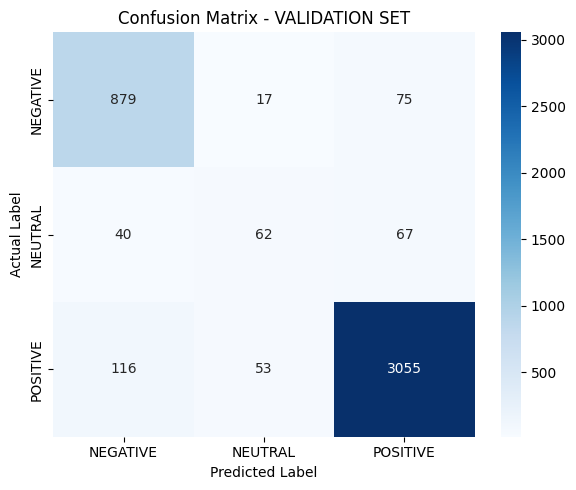

Model saved to: ../models/classifiers/svm_weighted.joblib and ../models/vectorizers/tfidf_weighted.joblib


In [74]:
import sys, os
from pathlib import Path

VECTORIZER_DIR = Path("../models/vectorizers")
MODEL_DIR = Path("../models/classifiers")

VECTORIZER_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# File names updated to include "weighted"
TFIDF_WEIGHTED_PATH = VECTORIZER_DIR / "tfidf_weighted.joblib"
SVM_WEIGHTED_PATH = MODEL_DIR / "svm_weighted.joblib"

# 2. Define sample weights for each review complexity level
sample_weight_map = {
    "COMPLEX": 3.0,
    "INFORMATIVE": 2.0,
    "UNINFORMATIVE": 1.0,
}

# 3. Train and evaluate the weighted TF-IDF + SVM pipeline
pipeline_weighted = TFIDF_SVM_Baseline(
    df_train=train_df,
    df_val=val_df,
    df_test=test_df,
    target_col="sentiment",
    text_col="review_cleaned_normed",
    max_features=100000,
    ngram_range=(1, 2),
    stop_words=None,
    do_preprocess=False,
    weight_col="weight",
    sample_weight_map=sample_weight_map,
).fit_pipeline(
    model_path=SVM_WEIGHTED_PATH,
    vec_path=TFIDF_WEIGHTED_PATH,
    keep_model=True,
    final=False,
)


### C.2 indoBERT

In [73]:
from transformers import AutoTokenizer
model_tokenizer = "indobenchmark/indobert-base-p1"

tokenizer = AutoTokenizer.from_pretrained(model_tokenizer)
sample_text = df["review_cleaned_normed"].iloc[9]

inputs = tokenizer(
    sample_text,
    padding="max_length",  # Menyamakkan panjang urutan
    truncation=True,  # Memotong teks jika melebihi max_length
    max_length=128,  # Panjang maksimum token (biasanya 128 atau 256)
    return_tensors="pt",  # Mengembalikan format PyTorch Tensor
)

print(inputs["input_ids"])  # ID Angka untuk setiap token
print(inputs["attention_mask"])  # Masking untuk padding (1 untuk kata asli, 0 untuk padding)

ModuleNotFoundError: No module named 'transformers'

In [ ]:
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding

tokenizer = AutoTokenizer.from_pretrained(model_tokenizer)
raw_texts = df_final["review_cleaned_normed"].astype(str).tolist()

class IndoBERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts  = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )

        return {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "labels": torch.tensor(label, dtype=torch.long),
        }

train_df = df_final[df_final["split"] == "train"].reset_index(drop=True)
val_df = df_final[df_final["split"] == "val"].reset_index(drop=True)

train_dataset = IndoBERTDataset(
    train_df["review_cleaned_normed"].values,
    train_df["sentiment"].values,
    tokenizer,
)

val_dataset = IndoBERTDataset(
    val_df["review_cleaned_normed"].values, train_df["sentiment"].values, tokenizer
)

test_dataset = IndoBERTDataset(
    test_df["review_cleaned_normed"].values, train_df["sentiment"].values, tokenizer
)

train_loader = DataLoader(train_dataset, batch_size = 32, shuffle = True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

In [ ]:
real_text = tokenizer.decode(inputs["input_ids"][0])
print(real_text)

In [ ]:
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
tokens

In [ ]:
unk_id = tokenizer.unk_token_id 
unk_count = (inputs["input_ids"] == unk_id).sum().item()
print(f"Jumlah token [UNK]: {unk_count}")

INPUT_IDS DESCRIPTION:

- angka: 2 CLS -> Token khusus awal kalimat yang di auto-assign oleh indoBERT.

- Angka 1339, 92, 119, ...: Token ID untuk kata-kata dalam ulasanmu (misalnya "aplikasi", "bagus", "suka", dll).

- Deretan angka 0 di belakang: Token khusus [PAD] (padding). Karena kamu menetapkan max_length=128, sisa ruang kosong diisi angka 0 agar ukurannya pas 128 elemen.

- angka: 3 CLS -> Token khusus akhir kalimat yang di auto-assign oleh indoBERT.

ATTENTION MASK:
- 1 -> token asli
0 -> Token padding, diabaikan saat proses attention mechanism

In [ ]:
token_lengths = [
    len(tokenizer.encode(text, truncation=False))
    for text in df["review_cleaned_normed"]
]

print(pd.Series(token_lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

set max_length = 125

In [ ]:
class indoBERT():
    def __init__(self, debug = True):
        self.label = df["sentiment"].unique()
        self.num_labels = len(df["sentiment"].unique())

        self.id2label = {0: "negative", 1: "neutral", 2: "positive"}
        self.label2id = {"negative": 0, "neutral": 1, "positive": 2}

        if debug == True:
            print(
                  f"id2label:\t{self.id2label}", "\n"
                  f"label2id:\t{self.label2id}"
            )

        from transformers import AutoModelForSequenceClassification
        from transformers import Trainer, TrainingArguments

        self.model = AutoModelForSequenceClassification.from_pretrained(
            model_tokenizer,
            num_labels=len(id2label),
            id2label=id2label,
            label2id=label2id,
            ignore_mismatched_sizes=True,  # Mengabaikan perbedaan ukuran matriks bobot terakhir dari checkpoint lama
        )

        self.training_args = TrainingArguments(
            output_dir="./results",
            num_train_epochs=3,  # Biasanya 3-5 epoch cukup untuk fine-tuning BERT
            per_device_train_batch_size=32,
            per_device_eval_batch_size=32,
            learning_rate=2e-5,  # Learning rate kecil khusus Transformers (1e-5 s/d 5e-5)
            # evaluation_strategy="epoch",  # Evaluasi setiap selesai 1 epoch
            save_strategy="best",
            load_best_model_at_end=True,  # Simpan model dengan performa validation terbaik
            metric_for_best_model="f1_macro",  # Pakai F1-score sebagai acuan utama
            seed=42,
        )
        
        